# Iris Flower Classification: Logistic Regression vs. Decision Tree

**Machine Learning & Data Science Internship Task**

This notebook builds and compares two supervised classification models on the classic **Iris** dataset.

**Workflow**
1. Load the dataset into a Pandas DataFrame
2. Exploratory data analysis (summary statistics, class balance, Seaborn pairplot, correlation heatmap)
3. Train/test split (80/20, stratified) and feature scaling with `StandardScaler`
4. Train `LogisticRegression` and `DecisionTreeClassifier`
5. Evaluate with accuracy, precision, recall, F1-score and full classification reports
6. Visualise confusion matrix heatmaps
7. Visualise decision boundaries (on two PCA components and on two petal features)

## 1. Setup and imports

In [20]:
# Core data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Scikit-learn: data, preprocessing, models and metrics
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Fixed random seed so every run gives the same split and the same tree
RANDOM_STATE = 42

# Consistent plot styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## 2. Load the dataset with Pandas

`load_iris(as_frame=True)` returns the data as a Pandas DataFrame. We add a readable `species` column
alongside the numeric `target` label.

In [21]:
iris = load_iris(as_frame=True)

df = iris.frame.copy()                                   # 4 feature columns + 'target'
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

feature_names = iris.feature_names                      # e.g. 'sepal length (cm)'
class_names = list(iris.target_names)                   # ['setosa', 'versicolor', 'virginica']

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 150 rows x 6 columns


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Exploratory data analysis

### 3.1 Structure, missing values and summary statistics

In [22]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [23]:
# Descriptive statistics for the four numeric features
df[feature_names].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


### 3.2 Class balance

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


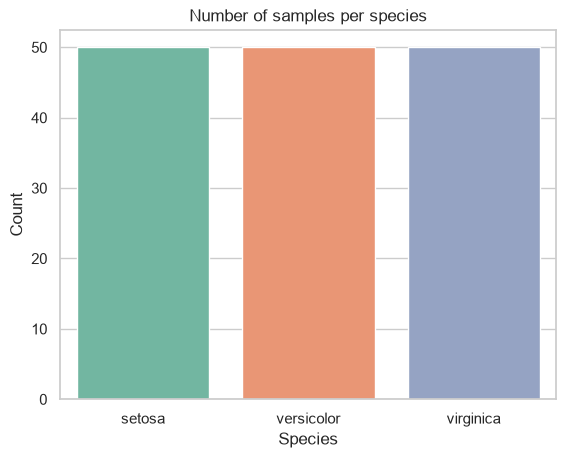

In [24]:
# A balanced dataset means accuracy is a fair headline metric
print(df["species"].value_counts())

ax = sns.countplot(data=df, x="species", hue="species", palette="Set2", legend=False)
ax.set_title("Number of samples per species")
ax.set_xlabel("Species")
ax.set_ylabel("Count")
plt.show()

### 3.3 Pairplot

The pairplot shows every pair of features coloured by species, with each feature's distribution on the diagonal.

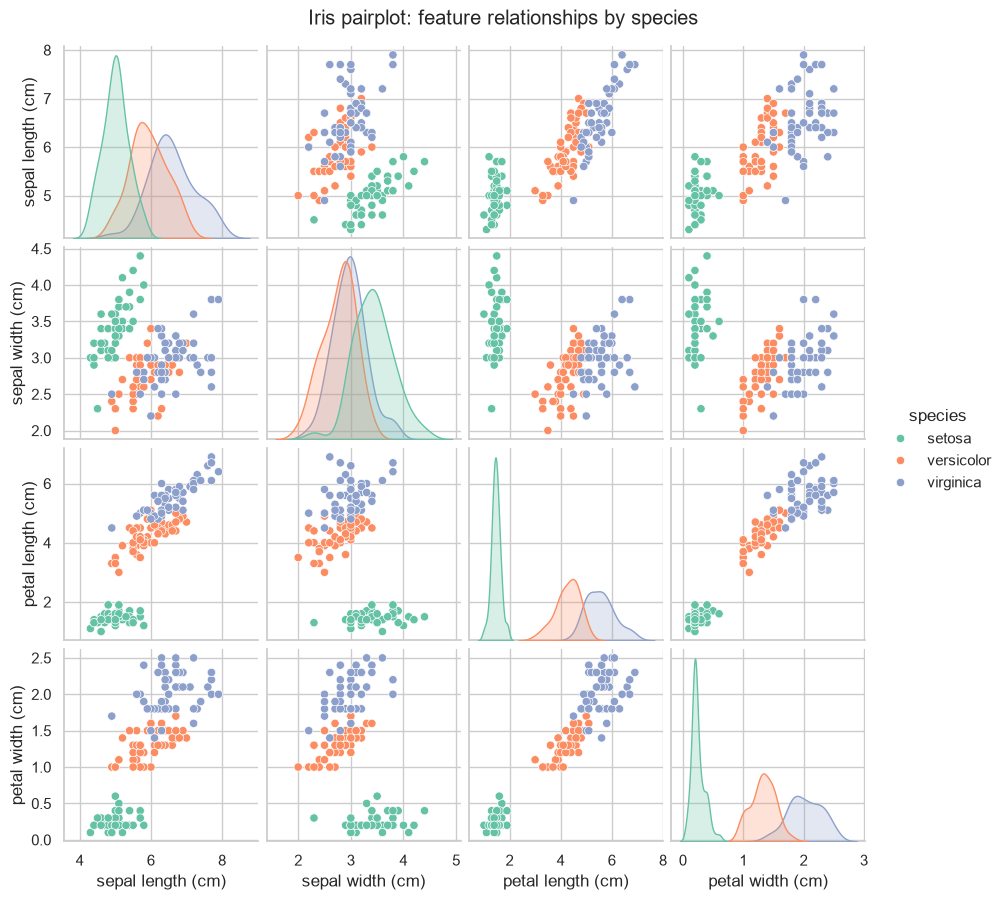

In [25]:
pair = sns.pairplot(df.drop(columns="target"), hue="species", palette="Set2",
                    diag_kind="kde", corner=False, height=2.2)
pair.figure.suptitle("Iris pairplot: feature relationships by species", y=1.02)
plt.show()

**Observations**
- *Setosa* is completely separated from the other two species by petal length and petal width.
- *Versicolor* and *virginica* overlap a little, mainly on the sepal measurements, so most classification errors are expected between these two.
- Petal features look far more informative than sepal features.

### 3.4 Correlation heatmap

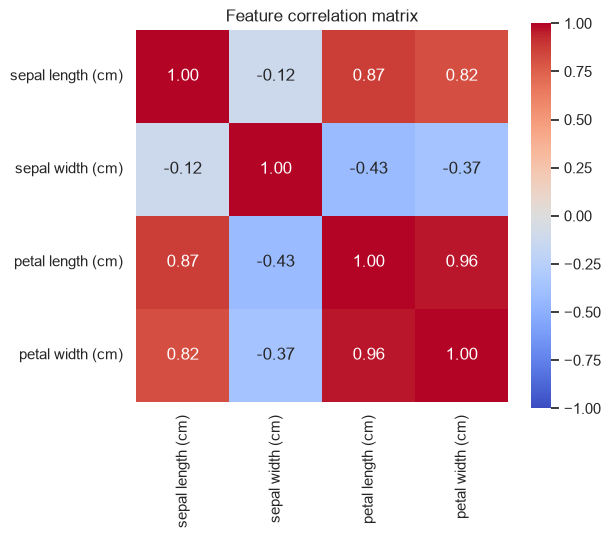

In [26]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[feature_names].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Feature correlation matrix")
plt.show()

Petal length and petal width are very strongly correlated (about 0.96), and both correlate strongly with sepal length.

## 4. Train/test split (80/20) and feature scaling

- `stratify=y` keeps the same class proportions in the train and test sets.
- `StandardScaler` is **fitted on the training set only** and then applied to the test set, so no information
  from the test data leaks into training.

In [27]:
X = df[feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean / std from training data
X_test_scaled = scaler.transform(X_test)         # reuse the same mean / std on test data

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print("\nTraining-set feature means after scaling (should be ~0):", X_train_scaled.mean(axis=0).round(3))
print("Training-set feature stds after scaling  (should be ~1):", X_train_scaled.std(axis=0).round(3))

Training set: 120 samples
Test set:     30 samples

Training-set feature means after scaling (should be ~0): [-0. -0.  0.  0.]
Training-set feature stds after scaling  (should be ~1): [1. 1. 1. 1.]


## 5. Model training

Two models with very different inductive biases:
- **Logistic Regression**: a linear model; it produces straight-line (hyperplane) decision boundaries.
- **Decision Tree**: a non-linear model that splits the feature space into axis-aligned rectangles.
  Scaling does not change a tree's splits, but we use the same scaled inputs for a like-for-like comparison.

In [28]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree


## 6. Evaluation

We report accuracy plus **macro-averaged** precision, recall and F1-score (each class weighted equally),
followed by the full per-class classification report for each model.

In [29]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


In [30]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(f"Classification report: {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Classification report: Logistic Regression
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

Classification report: Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



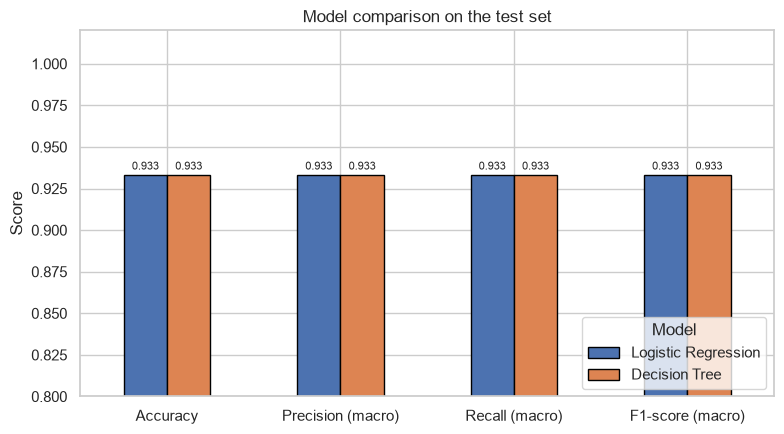

In [31]:
# Side-by-side bar chart of the four metrics
ax = results.T.plot(kind="bar", figsize=(8, 4.5), color=["#4C72B0", "#DD8452"], edgecolor="black")
ax.set_ylim(0.8, 1.02)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the test set")
ax.legend(title="Model", loc="lower right")
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

### 6.1 Confusion matrix heatmaps

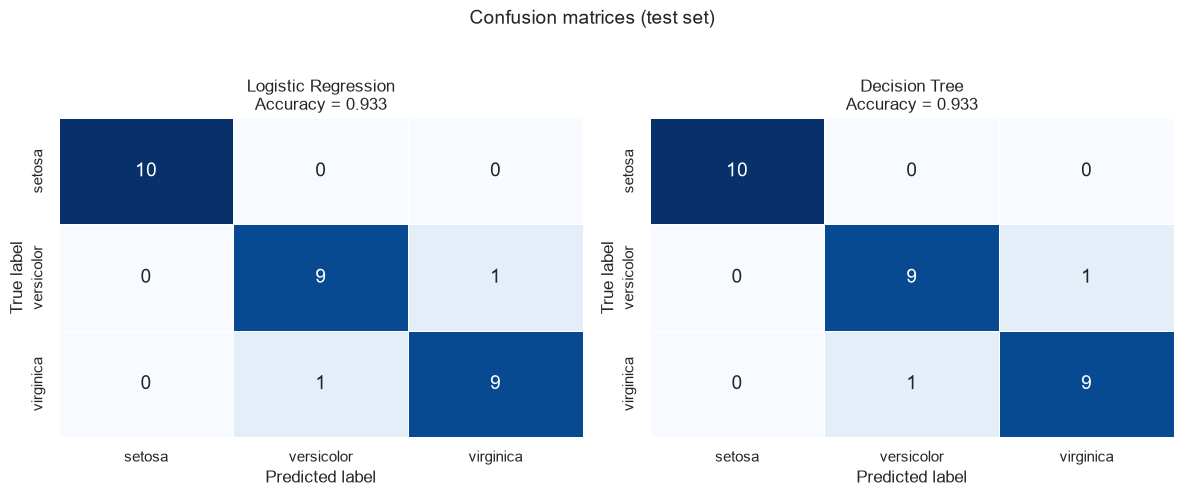

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor="white", annot_kws={"size": 14})
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.suptitle("Confusion matrices (test set)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

Diagonal cells are correct predictions; any off-diagonal count is a misclassification. As the pairplot suggested,
*setosa* is always classified correctly and the few errors fall between *versicolor* and *virginica*.

### 6.2 Inspecting the trained models

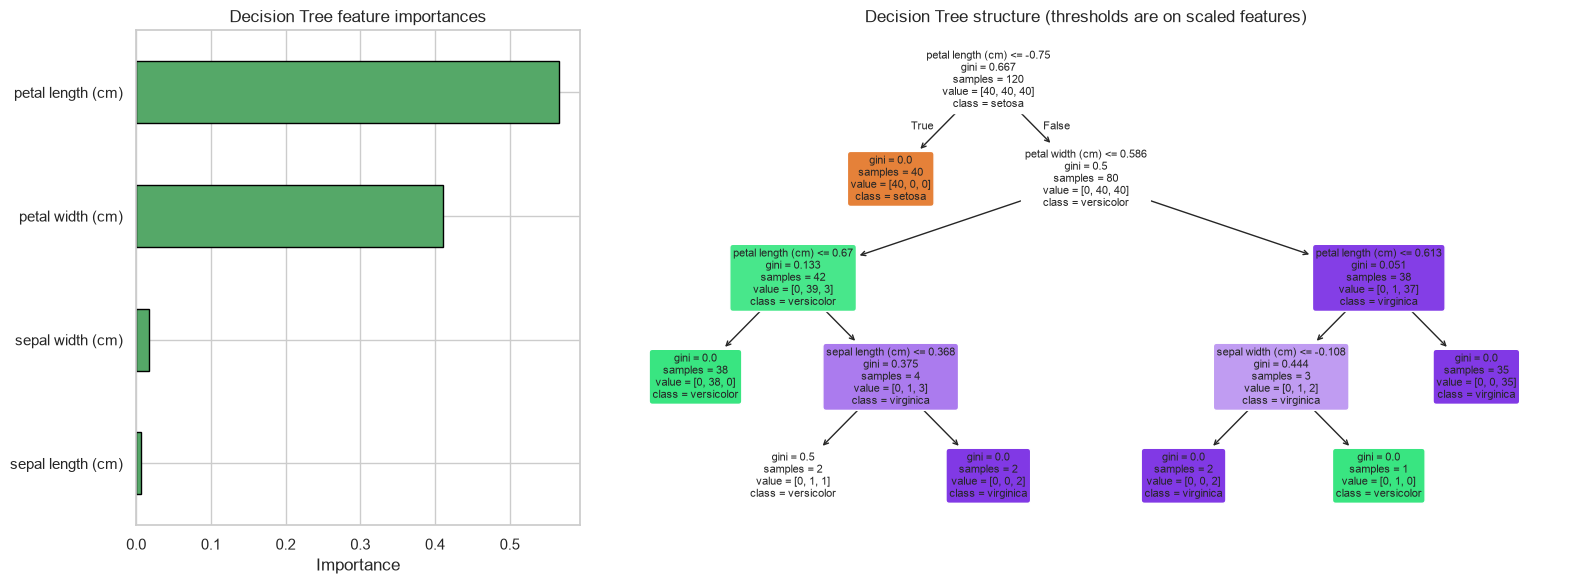

In [33]:
# Decision Tree: which features drive the splits?
tree = models["Decision Tree"]
importances = pd.Series(tree.feature_importances_, index=feature_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2.2]})
importances.plot(kind="barh", ax=axes[0], color="#55A868", edgecolor="black")
axes[0].set_title("Decision Tree feature importances")
axes[0].set_xlabel("Importance")

plot_tree(tree, feature_names=feature_names, class_names=class_names, filled=True,
          rounded=True, fontsize=8, ax=axes[1])
axes[1].set_title("Decision Tree structure (thresholds are on scaled features)")
plt.tight_layout()
plt.show()

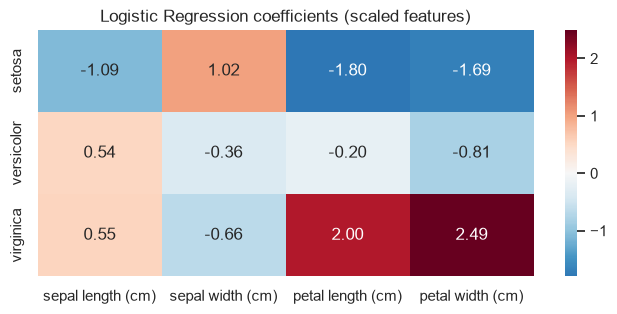

In [34]:
# Logistic Regression: one coefficient per (class, feature) on the scaled inputs
coef = pd.DataFrame(models["Logistic Regression"].coef_, index=class_names, columns=feature_names)
plt.figure(figsize=(8, 3.2))
sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Logistic Regression coefficients (scaled features)")
plt.show()

## 7. Decision boundary visualisation

A decision boundary can only be drawn in 2D, so we train fresh copies of both models on two-dimensional inputs:

1. **PCA projection**: the four scaled features compressed into their first two principal components.
2. **Petal length vs. petal width**: the two most informative original features.

The coloured regions show which class each model would predict at every point of the plane; the markers are the
real samples (circles = training, crosses = test).

In [35]:
def plot_decision_boundaries(X_tr, X_te, y_tr, y_te, xlabel, ylabel, title):
    """Fit both model types on 2D data and draw their decision regions side by side."""
    cmap_bg = ListedColormap(["#c6dbef", "#fdd0a2", "#c7e9c0"])   # light region colours
    point_colors = ["#2171b5", "#d94801", "#238b45"]                # strong point colours

    # Build a fine grid covering the data range
    X_all = np.vstack([X_tr, X_te])
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    for ax, (name, template) in zip(axes, models.items()):
        clf = template.__class__(**template.get_params())        # fresh, unfitted copy
        clf.fit(X_tr, y_tr)
        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.8)
        ax.contour(xx, yy, Z, colors="grey", linewidths=0.6)

        for cls, color in enumerate(point_colors):
            ax.scatter(X_tr[y_tr == cls, 0], X_tr[y_tr == cls, 1], c=color, marker="o",
                       edgecolor="black", s=35, label=f"{class_names[cls]} (train)")
            ax.scatter(X_te[y_te == cls, 0], X_te[y_te == cls, 1], c=color, marker="X",
                       edgecolor="black", s=80, label=f"{class_names[cls]} (test)")

        acc = accuracy_score(y_te, clf.predict(X_te))
        ax.set_title(f"{name}  |  2D test accuracy = {acc:.3f}")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.06), fontsize=9)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

### 7.1 Decision boundaries on the first two principal components

Variance explained: PC1 = 72.7%, PC2 = 23.1%, total = 95.7%


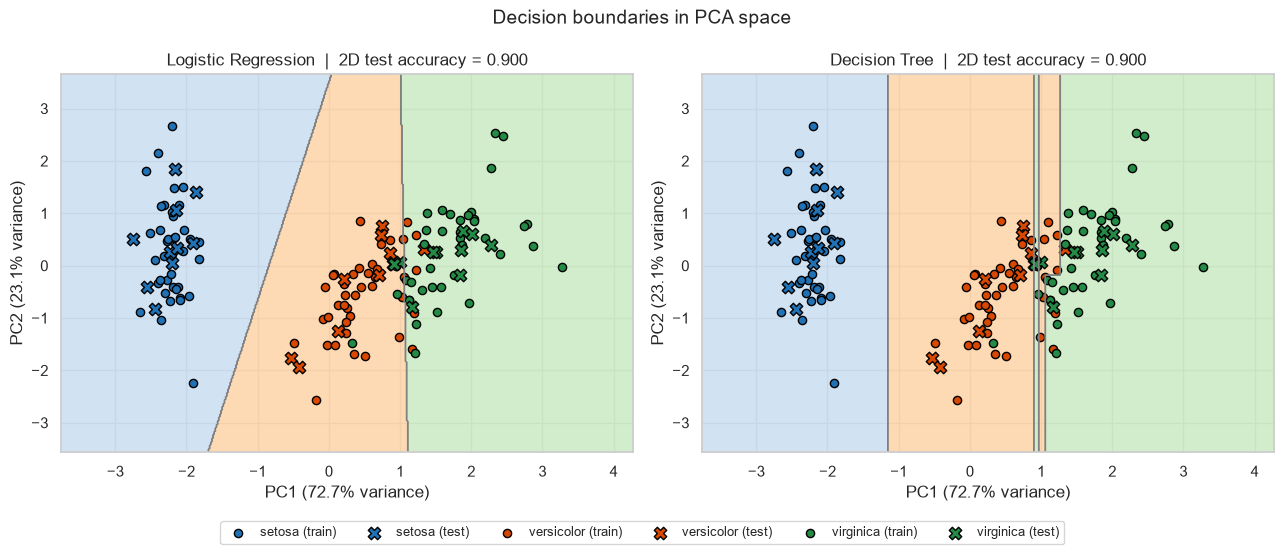

In [36]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)   # fit PCA on training data only
X_test_pca = pca.transform(X_test_scaled)

explained = pca.explained_variance_ratio_
print(f"Variance explained: PC1 = {explained[0]:.1%}, PC2 = {explained[1]:.1%}, total = {explained.sum():.1%}")

plot_decision_boundaries(
    X_train_pca, X_test_pca, y_train.to_numpy(), y_test.to_numpy(),
    xlabel=f"PC1 ({explained[0]:.1%} variance)", ylabel=f"PC2 ({explained[1]:.1%} variance)",
    title="Decision boundaries in PCA space",
)

### 7.2 Decision boundaries on petal length and petal width (scaled)

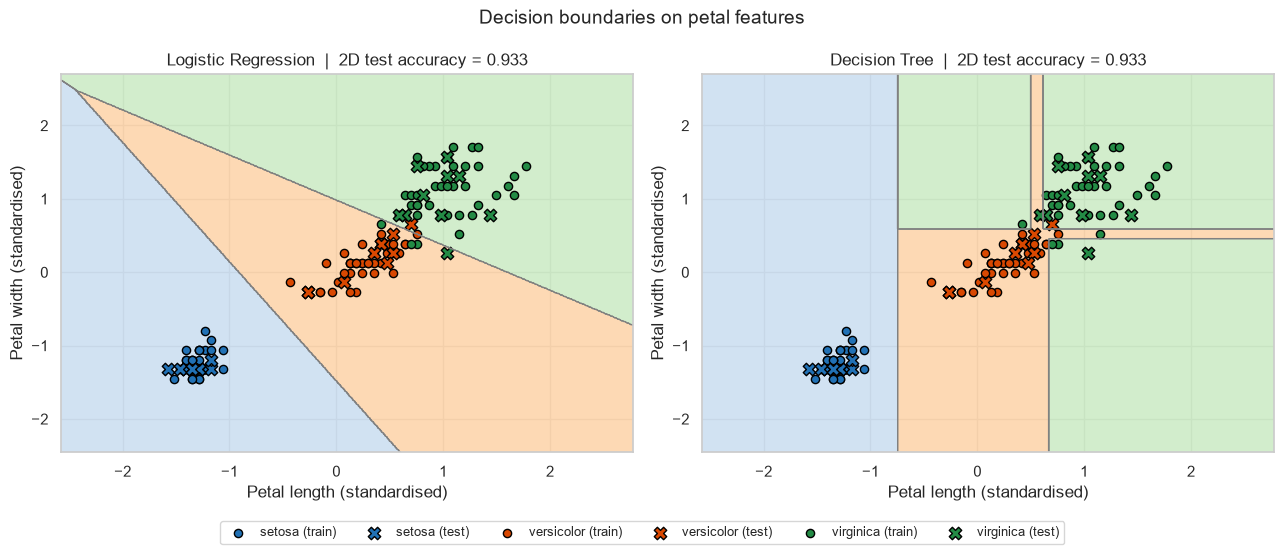

In [37]:
petal_idx = [feature_names.index("petal length (cm)"), feature_names.index("petal width (cm)")]

plot_decision_boundaries(
    X_train_scaled[:, petal_idx], X_test_scaled[:, petal_idx], y_train.to_numpy(), y_test.to_numpy(),
    xlabel="Petal length (standardised)", ylabel="Petal width (standardised)",
    title="Decision boundaries on petal features",
)

Logistic Regression draws smooth, straight boundaries between classes, while the Decision Tree carves the plane
into axis-aligned rectangles. Both isolate *setosa* easily; the interesting differences are in the region where
*versicolor* and *virginica* meet.

## 8. Conclusion

In [38]:
print("Final test-set metrics:\n")
print(results.to_string())

f1 = results["F1-score (macro)"]
top = f1[f1 == f1.max()].index.tolist()
if len(top) > 1:
    print(f"\nBoth models tie on macro F1-score ({f1.max():.4f}) on this test split.")
else:
    print(f"\nBest model by macro F1-score: {top[0]}")

Final test-set metrics:

                     Accuracy  Precision (macro)  Recall (macro)  F1-score (macro)
Model                                                                             
Logistic Regression    0.9333             0.9333          0.9333            0.9333
Decision Tree          0.9333             0.9333          0.9333            0.9333

Both models tie on macro F1-score (0.9333) on this test split.


**Summary**
- The Iris dataset is small, clean and balanced, with no missing values.
- Petal measurements are the most discriminative features; *setosa* is linearly separable from the other species.
- Both models reach about 93% accuracy, precision, recall and F1 on the held-out 30-sample test set (2 errors each),
  and every error is a *versicolor*/*virginica* mix-up.
- Logistic Regression's linear boundaries suit this data well, and it is less prone to overfitting than a deep tree.
  The Decision Tree (limited to depth 4) is easy to interpret and confirms petal width and length as the key features.

**Possible next steps**
- Use k-fold cross-validation for a more robust estimate than a single 30-sample test set.
- Tune hyperparameters (`C` for Logistic Regression, `max_depth` / `min_samples_leaf` for the tree) with `GridSearchCV`.
- Repeat the pipeline on the Wine dataset (`sklearn.datasets.load_wine`) to compare on a harder, 13-feature problem.